# Subject-Specific 4-Alpha Model (Task $\times$ Valence) & Variance Explained by GAD-7 (`16b`)

Whereas **Notebook 16** constrains between-subject variation in the four learning rates to be purely a deterministic function of GAD-7, **this notebook (`16b`)** estimates **subject-specific** learning rates for all four Task $\times$ Valence conditions by including hierarchical individual random effects ($z_{k, i} \cdot \sigma_k$) alongside the GAD-7 predictor:

$$\text{logit}(\alpha_{k, i}) = \text{intercept}_k + \text{slope}_k \cdot \text{GAD7}_{\text{norm}, i} + z_{k, i} \cdot \sigma_k, \quad k \in \{\text{win\_pos}, \text{win\_neg}, \text{lose\_pos}, \text{lose\_neg}\}$$

### Key Outputs:
1. **Hierarchical GAD-7 Slopes (`slope_win_pos`, `slope_win_neg`, `slope_lose_pos`, `slope_lose_neg`):** Posterior distributions and 89% HDIs when accounting for between-subject random variance.
2. **Variance Explained ($R^2$) by GAD-7 for Each of the 4 Learning Rates:**
   - **Bayesian Latent $R^2$ (logit scale):** $\frac{\text{Var}(\text{slope}_k \cdot \text{GAD7}_{\text{norm}})}{\text{Var}(\text{slope}_k \cdot \text{GAD7}_{\text{norm}}) + \sigma_k^2}$ across posterior draws.
   - **Subject-Level Empirical $R^2$:** Proportion of variance in the $N = 67$ subject-specific posterior mean learning rates explained by GAD-7.
3. **Subject-Specific $4 \times 4$ Learning Rate Correlation Matrix:** Tests how the 4 learning rates co-vary across participants.


In [1]:
import pandas as pd
import numpy as np
import pymc as pm
import pytensor
import pytensor.tensor as pt
import matplotlib.pyplot as plt
import seaborn as sns
import arviz as az
from scipy import stats
import warnings

from learning_functions import prepare_vectorized_bandit_data, step_m4_vec, get_hdi_bounds, plot_posterior_hdi

warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid")


In [2]:
# Load Data and Vectorize across Subjects
file_path = '../data/allsubs_combined.csv'
df_raw = pd.read_csv(file_path).dropna(subset=['ChoiceKey', 'GAD7']).reset_index(drop=True).copy()

stim_map = {'W1': 0, 'W2': 1, 'L1': 2, 'L2': 3}
df_raw['LeftID_int'] = df_raw['LeftID'].map(stim_map)
df_raw['RightID_int'] = df_raw['RightID'].map(stim_map)
df_raw['ChosenID_int'] = df_raw['ChosenID'].map(stim_map)
df_raw['Choice'] = (df_raw['ChoiceKey'] - 1).astype(int)
df_raw['RewardScaled'] = df_raw['TrialPoints'] / 30.0

vdata = prepare_vectorized_bandit_data(df_raw)
df = vdata['df']
n_sub = vdata['n_sub']
unique_subs = vdata['unique_subs']

sub_gad7_map = df.groupby('SubIdx')['GAD7'].first()
gad7_scores = np.array([sub_gad7_map[i] for i in range(n_sub)])
gad7_normalized = gad7_scores / 21.0

print(f"Total subjects included: {n_sub}")
print(f"Total trials: {len(df)} (Vectorized scan length: {vdata['max_t']} steps)")


Total subjects included: 67
Total trials: 6520 (Vectorized scan length: 100 steps)


In [3]:
def build_hierarchical_gad7_4alpha_model(vdata, gad7_normalized):
    n_sub, t_idx, s_idx = vdata['n_sub'], vdata['t_idx'], vdata['s_idx']
    with pm.Model() as model:
        gad7_data = pm.Data("gad7_data", gad7_normalized)
        
        alphas = {}
        for name in ['win_pos', 'win_neg', 'lose_pos', 'lose_neg']:
            intercept = pm.Normal(f'intercept_{name}', mu=0, sigma=1.5)
            slope = pm.Normal(f'slope_{name}', mu=0, sigma=1.5)
            sigma = pm.HalfNormal(f'sigma_{name}', sigma=1.0)
            raw = pm.Normal(f'raw_{name}', mu=0, sigma=1, shape=n_sub)
            alphas[name] = pm.Deterministic(
                f'alpha_{name}',
                pm.math.invlogit(intercept + slope * gad7_data + raw * sigma)
            )
        
        mu_beta_log = pm.Normal('mu_beta_log', mu=0, sigma=2.0)
        sigma_beta = pm.HalfNormal('sigma_beta', sigma=1.0)
        beta_raw = pm.Normal('beta_raw', mu=0, sigma=1, shape=n_sub)
        beta = pm.Deterministic('beta', pm.math.exp(mu_beta_log + beta_raw * sigma_beta))
        
        Q_init = pt.zeros((n_sub, 4))
        results = pytensor.scan(
            fn=step_m4_vec,
            sequences=[
                pt.as_tensor_variable(vdata['left_oh']),
                pt.as_tensor_variable(vdata['right_oh']),
                pt.as_tensor_variable(vdata['chosen_oh']),
                pt.as_tensor_variable(vdata['rew_mat']),
                pt.as_tensor_variable(vdata['win_mat']),
            ],
            outputs_info=[Q_init, None, None, None],
            non_sequences=[alphas['win_pos'], alphas['win_neg'], alphas['lose_pos'], alphas['lose_neg']],
            strict=True,
            return_updates=False
        )
        q_left_seq = results[1][t_idx, s_idx]
        q_right_seq = results[2][t_idx, s_idx]
        p_right_raw = pm.math.sigmoid(beta[s_idx] * (q_right_seq - q_left_seq))
        p_right = pm.Deterministic('p_right', pt.clip(p_right_raw, 1e-5, 1.0 - 1e-5))
        pm.Bernoulli('choice_obs', p=p_right, observed=vdata['df']['Choice'].values)
    return model

print("Building vectorized hierarchical subject-specific 4-Alpha GAD-7 model...")
m_hier_4a = build_hierarchical_gad7_4alpha_model(vdata, gad7_normalized)


Building vectorized hierarchical subject-specific 4-Alpha GAD-7 model...


In [4]:
print("Sampling posterior using nutpie (PyMC 6)...")
with m_hier_4a:
    idata = pm.sample(nuts_sampler="nutpie", draws=1000, tune=1000, chains=4, progressbar=True)
print("Sampling complete!")


Sampling posterior using nutpie (PyMC 6)...


NUTS[nutpie]: [intercept_win_pos, slope_win_pos, sigma_win_pos, raw_win_pos, intercept_win_neg, slope_win_neg, sigma_win_neg, raw_win_neg, intercept_lose_pos, slope_lose_pos, sigma_lose_pos, raw_lose_pos, intercept_lose_neg, slope_lose_neg, sigma_lose_neg, raw_lose_neg, mu_beta_log, sigma_beta, beta_raw]


Output()

Sampling complete!


In [5]:
rate_names = ['win_pos', 'win_neg', 'lose_pos', 'lose_neg']
rate_labels = {
    'win_pos': 'Win Positive PE (alpha_win_pos)',
    'win_neg': 'Win Negative PE (alpha_win_neg)',
    'lose_pos': 'Loss Positive PE (alpha_lose_pos)',
    'lose_neg': 'Loss Negative PE (alpha_lose_neg)',
}
rate_colors = {
    'win_pos': 'teal',
    'win_neg': 'steelblue',
    'lose_pos': 'darkorange',
    'lose_neg': 'purple',
}

var_gad7_norm = np.var(gad7_normalized, ddof=1)

sub_params = {'Sub': unique_subs, 'GAD7': gad7_scores}
r2_latent_dict = {}

print("========================================================================================")
print("HIERARCHICAL SUBJECT-SPECIFIC 4-ALPHA + GAD-7 RESULTS (89% HDI)")
print("========================================================================================")
for name in rate_names:
    s_draws = idata.posterior[f'slope_{name}'].values.flatten()
    sig_draws = idata.posterior[f'sigma_{name}'].values.flatten()
    s_low, s_high = get_hdi_bounds(idata, f'slope_{name}', prob=0.89)
    sig_low, sig_high = get_hdi_bounds(idata, f'sigma_{name}', prob=0.89)
    
    var_exp = (s_draws ** 2) * var_gad7_norm
    r2_draws = var_exp / (var_exp + sig_draws ** 2)
    r2_latent_dict[name] = r2_draws
    
    a_samples = idata.posterior[f'alpha_{name}'].values.reshape(-1, n_sub)
    sub_params[f'alpha_{name}'] = a_samples.mean(axis=0)
    
    print(f"{rate_labels[name]:35s} | Slope = {s_draws.mean():+.3f} [{s_low:+.3f}, {s_high:+.3f}] | Sigma = {sig_draws.mean():.3f} [{sig_low:.3f}, {sig_high:.3f}]")

sub_params['beta'] = idata.posterior['beta'].values.reshape(-1, n_sub).mean(axis=0)
df_sub_4a = pd.DataFrame(sub_params)
df_sub_4a.to_csv('../data/rl_4alpha_subject_parameters.csv', index=False)

print("\n----------------------------------------------------------------------------------------")
print("VARIANCE EXPLAINED (R^2) BY GAD-7 ACROSS THE 4 LEARNING RATES")
print("----------------------------------------------------------------------------------------")
for name in rate_names:
    r2_draws = r2_latent_dict[name]
    r2_hdi = np.quantile(r2_draws, [0.055, 0.945])
    r_emp, p_emp = stats.pearsonr(gad7_scores, df_sub_4a[f'alpha_{name}'])
    print(f"{rate_labels[name]:35s} | Latent R^2 = {r2_draws.mean()*100:5.2f}% (89% HDI [{r2_hdi[0]*100:4.2f}%, {r2_hdi[1]*100:5.2f}%]) | Empirical r = {r_emp:+.3f}, R^2 = {(r_emp**2)*100:4.2f}% (p = {p_emp:.4f})")

print("\n----------------------------------------------------------------------------------------")
print(f"SUBJECT-SPECIFIC 4x4 PEARSON CORRELATION MATRIX (N = {n_sub})")
print("----------------------------------------------------------------------------------------")
alpha_cols = [f'alpha_{name}' for name in rate_names]
corr_mat = df_sub_4a[alpha_cols].corr(method='pearson')
print(corr_mat.round(3).to_string())
print("========================================================================================\n")


HIERARCHICAL SUBJECT-SPECIFIC 4-ALPHA + GAD-7 RESULTS (89% HDI)
Win Positive PE (alpha_win_pos)     | Slope = +0.477 [-1.152, +2.066] | Sigma = 1.415 [0.930, 1.878]
Win Negative PE (alpha_win_neg)     | Slope = +0.648 [-1.135, +2.380] | Sigma = 1.556 [0.792, 2.223]
Loss Positive PE (alpha_lose_pos)   | Slope = +0.282 [-1.671, +2.217] | Sigma = 1.624 [0.667, 2.518]
Loss Negative PE (alpha_lose_neg)   | Slope = -0.579 [-2.385, +1.220] | Sigma = 1.823 [1.349, 2.245]

----------------------------------------------------------------------------------------
VARIANCE EXPLAINED (R^2) BY GAD-7 ACROSS THE 4 LEARNING RATES
----------------------------------------------------------------------------------------
Win Positive PE (alpha_win_pos)     | Latent R^2 =  3.10% (89% HDI [0.01%, 11.64%]) | Empirical r = +0.154, R^2 = 2.36% (p = 0.2146)
Win Negative PE (alpha_win_neg)     | Latent R^2 =  4.08% (89% HDI [0.01%, 14.64%]) | Empirical r = +0.253, R^2 = 6.39% (p = 0.0390)
Loss Positive PE (alpha_l

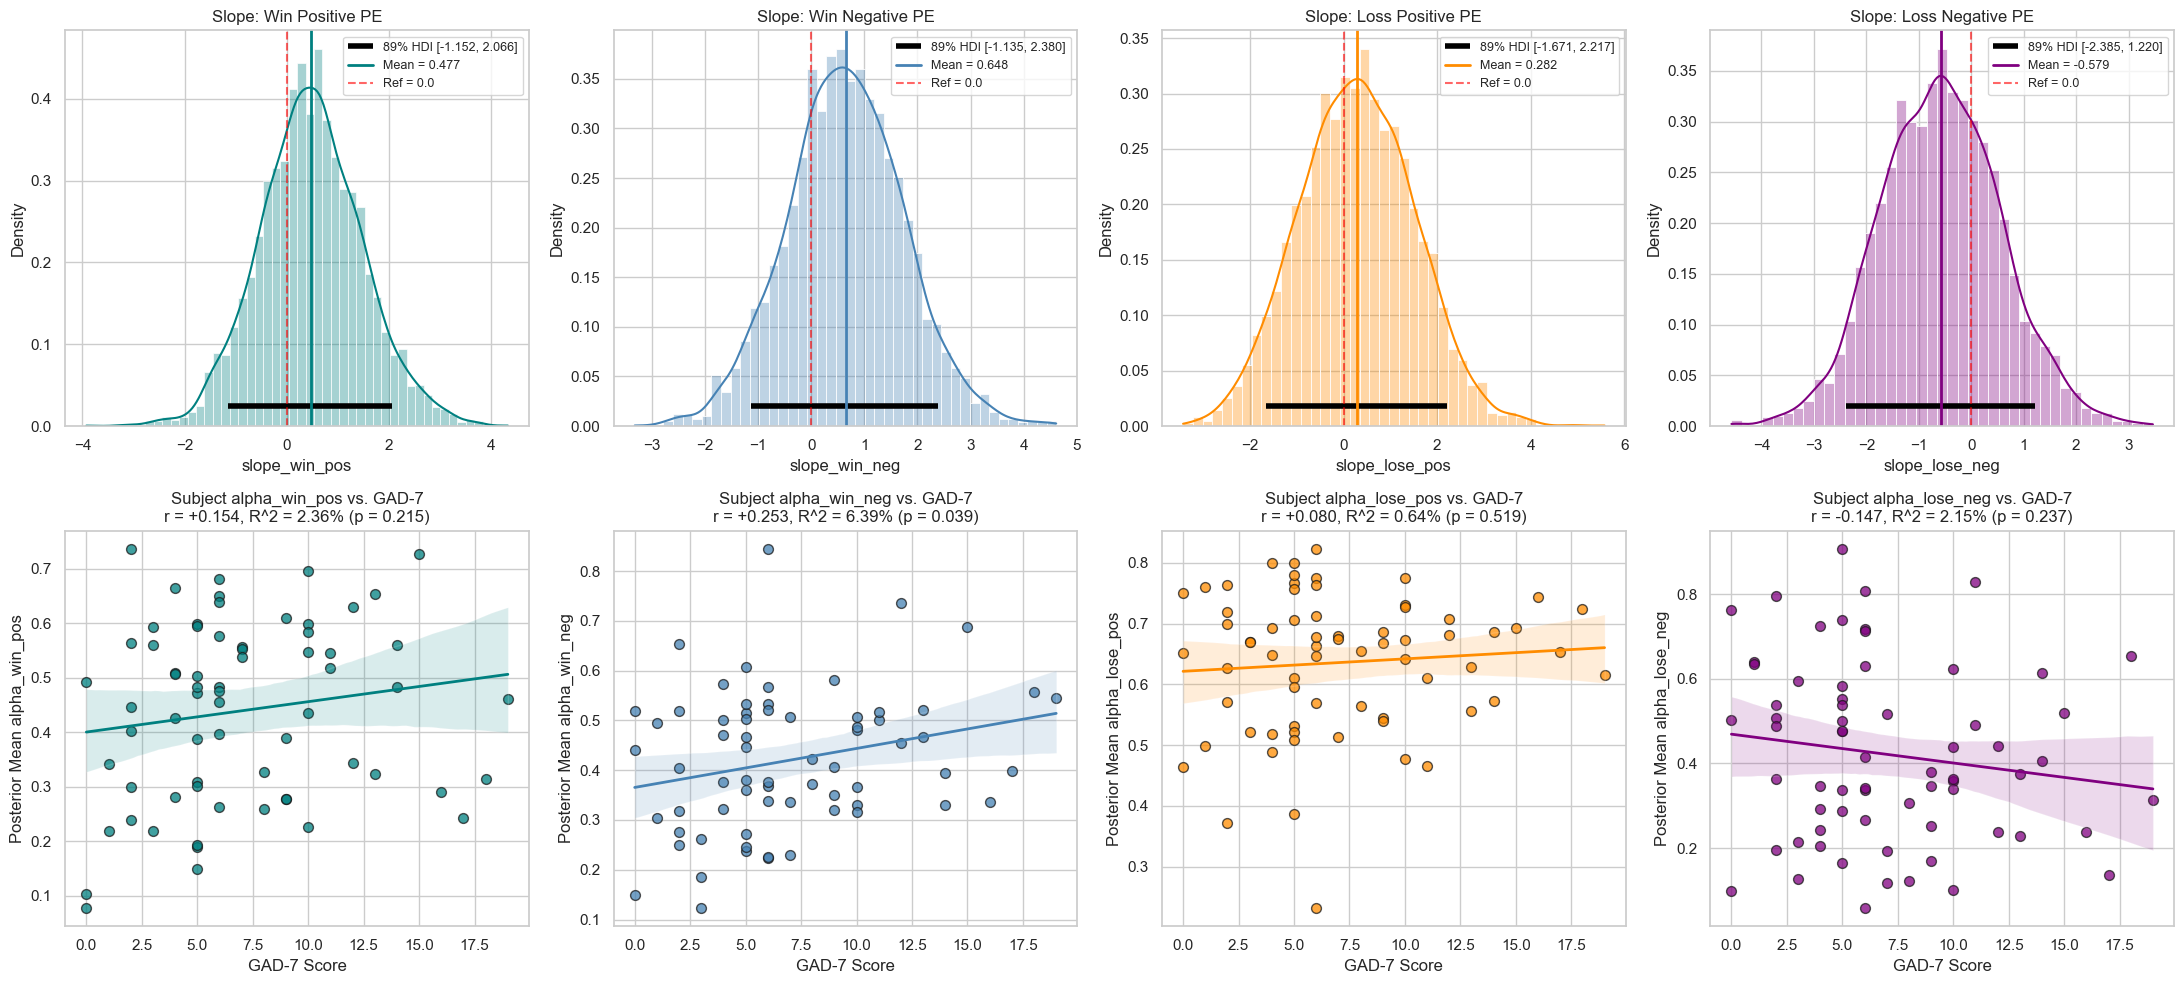

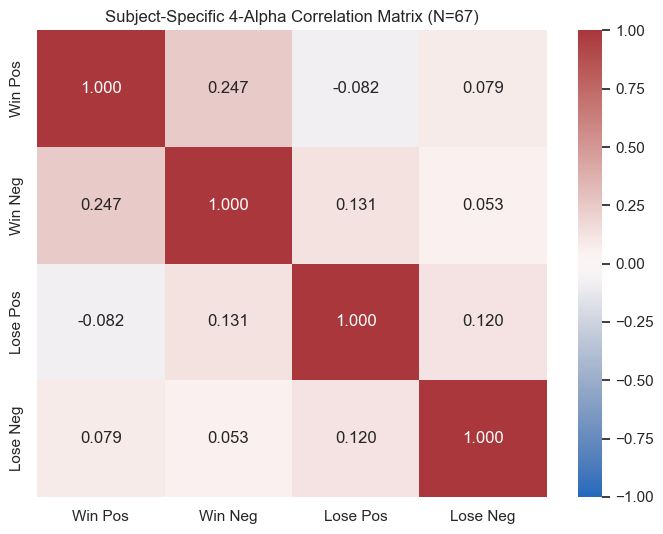

In [6]:
# Plot Slopes, Subject-Specific Regressions vs. GAD-7, and 4x4 Correlation Heatmap
fig, axes = plt.subplots(2, 4, figsize=(22, 10))

for idx, name in enumerate(rate_names):
    color = rate_colors[name]
    # Top row: Posterior of hierarchical slope
    plot_posterior_hdi(idata, f'slope_{name}', prob=0.89, ax=axes[0, idx], color=color,
                       title=f"Slope: {rate_labels[name].split(' (')[0]}")
    
    # Bottom row: Subject-specific alpha vs GAD-7
    y_vals = df_sub_4a[f'alpha_{name}'].values
    r_emp, p_emp = stats.pearsonr(gad7_scores, y_vals)
    sns.regplot(x=gad7_scores, y=y_vals, ax=axes[1, idx], color=color,
                scatter_kws={'alpha': 0.75, 's': 50, 'edgecolor': 'k'}, line_kws={'linewidth': 2})
    axes[1, idx].set_title(f"Subject {f'alpha_{name}'} vs. GAD-7\nr = {r_emp:+.3f}, R^2 = {(r_emp**2)*100:.2f}% (p = {p_emp:.3f})")
    axes[1, idx].set_xlabel("GAD-7 Score")
    axes[1, idx].set_ylabel(f"Posterior Mean alpha_{name}")

plt.tight_layout()
plt.savefig('../data/alpha_4rates_vs_gad7_nb16b.png', dpi=150, bbox_inches='tight')
plt.show()

# 4x4 Pairplot / Heatmap of Subject-Specific Learning Rates
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr_mat, annot=True, fmt=".3f", cmap="vlag", vmin=-1, vmax=1, ax=ax,
            xticklabels=['Win Pos', 'Win Neg', 'Lose Pos', 'Lose Neg'],
            yticklabels=['Win Pos', 'Win Neg', 'Lose Pos', 'Lose Neg'])
ax.set_title(f"Subject-Specific 4-Alpha Correlation Matrix (N={n_sub})")
plt.tight_layout()
plt.show()
